# Experiment B — CNN-LSTM-CTC, IAM test only
Replicate Experiment A's IAM comparison using the frozen epoch 14 CNN checkpoint: baseline and six individual preprocessing techniques. No training, combinations, Bentham or RIMES evaluation. This replaces the original planned meaning of Experiment B (combined preprocessing).

Use the same 1000 IAM test lines, sorted NumPy sampling without replacement with seed 5112, and pinned IAM revision as Experiment A. This extends the older CNN plan's 250-line scope to match Experiment A. No test-based tuning. Active settings are now selected by CNN-specific corpus CER then WER on the fixed 100 IAM validation lines, using the prespecified grids. Exact ties retain grid order. Selection provenance and checkpoint hash are checked and saved. These are best within the tested grid, not global optima. Earlier runs using transferred TrOCR settings remain separate. Baseline remains separate even if a technique is worse.

The recognizer always applies its checkpoint's mandatory grayscale/height-64 preparation after optional treatments. Optional grayscale may therefore have little or no effect; optional height-128 resizing is an extra resampling before mandatory resizing. Greedy CTC decoding and character vocabulary stay fixed. Corpus CER/WER collapse whitespace, preserving case and punctuation. Compare changes relative to each architecture's baseline: training provenance differs.

Independent notebook; previous notebooks need not be executed. Outputs: results/test/experiment_b/<UTC run ID>/.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from datetime import datetime, timezone
from importlib.metadata import version, packages_distributions, PackageNotFoundError
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/load_dataset/iam.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import cv2
from IPython.display import display
from src.load_dataset.iam import load_iam_dataset
from src.models import CNNLSTMCTCRecognizer
from src.preprocessing import PreprocessingPipeline, Grayscale, NonLocalMeans, Deskew, CLAHE, IntensityNormalization, SizeNormalization
from src.evaluation.recognition import compare_recognition
from src.validation.denoising import adapt_image
SPLIT = "test"
SAMPLE_COUNT = 1000
SEED = 5112
DATASET_REVISION = "fbdad97500ce54635c0d1ba306bf535cb40656cf"
CHECKPOINT = ROOT / "results/cnn_lstm_ctc/training/20261114_baseline/iam/best.pt"
# CPU matches the verified CNN inference workflow; packed LSTM stays portable.
DEVICE = "cpu"
torch.set_num_threads(4)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
from src.validation.cnn import configurations as cnn_validation_grids
VALIDATION_RUN = ROOT / "results/validation/cnn_iam/20261116T031934197602Z"
selection = json.loads((VALIDATION_RUN / "selected_settings.json").read_text())
assert selection["dataset_revision"] == DATASET_REVISION
registry = cnn_validation_grids()
pipelines = {"baseline": PreprocessingPipeline()}
for technique in ("grayscale", "denoising", "deskew", "clahe", "intensity_normalization", "size_normalization"):
    chosen = selection["settings"][technique]
    step = registry[technique][chosen["configuration"]]
    assert json.loads(json.dumps(step.to_config())) == chosen["parameters"]
    pipelines[technique] = PreprocessingPipeline((step,))
frozen_config = {name: pipe.to_config() for name, pipe in pipelines.items()}
display(pd.DataFrame([{"configuration": k, "parameters": json.dumps(v)} for k, v in frozen_config.items()]))

,configuration,parameters
0,baseline,"{""steps"": []}"
1,grayscale,"{""steps"": [{""name"": ""grayscale"", ""enabled"": tr..."
2,denoising,"{""steps"": [{""name"": ""non_local_means"", ""enable..."
3,deskew,"{""steps"": [{""name"": ""deskew"", ""enabled"": true,..."
4,clahe,"{""steps"": [{""name"": ""clahe"", ""enabled"": true, ..."
5,intensity_normalization,"{""steps"": [{""name"": ""intensity_normalization"",..."
6,size_normalization,"{""steps"": [{""name"": ""size_normalization"", ""ena..."


In [2]:
# Same ordered IAM source indices as Experiment A; only the test split is loaded.
assert SPLIT == "test" and SAMPLE_COUNT == 1000
full_dataset = load_iam_dataset(split=SPLIT, revision=DATASET_REVISION)
indices = sorted(np.random.default_rng(SEED).choice(len(full_dataset), min(SAMPLE_COUNT, len(full_dataset)), replace=False).tolist())
dataset = full_dataset.select(indices)
samples, manifest_rows = [], []
for index, row in zip(indices, dataset):
    if not isinstance(row["text"], str) or not row["text"].strip():
        raise ValueError(f"Missing transcription: {index}")
    image = adapt_image(row["image"])
    sample_id = f"sample_{index}"
    samples.append({"id": sample_id, "image": image, "ground_truth": row["text"]})
    manifest_rows.append({"sample_id": sample_id, "dataset_index": index, "ground_truth": row["text"],
                          "source_mode": row["image"].mode, "width": image.width, "height": image.height})
assert len({s["id"] for s in samples}) == len(samples)
sample_info = pd.DataFrame(manifest_rows)
print("IAM test split:", len(full_dataset), "| selected:", len(samples))
display(sample_info.head())

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


IAM test split: 2915 | selected: 1000


,sample_id,dataset_index,ground_truth,source_mode,width,height
0,sample_0,0,"assuredness "" Bella Bella Marie "" ( Parlophone...",L,2611,128
1,sample_6,6,He is also a director of a couple of garages ....,L,3232,128
2,sample_8,8,"The numbers include "" Scotland the Brave , "" ""...",L,2009,128
3,sample_9,9,"Fay Compton stars in "" No Hiding Place "" (I T ...",L,1692,128
4,sample_10,10,She plays the possessive mother of a man whose...,L,1552,128


In [3]:
recognizer = CNNLSTMCTCRecognizer.from_checkpoint(CHECKPOINT, device=DEVICE)
recognizer.model.eval()
model_config = recognizer.to_config()
assert model_config["checkpoint_epoch"] == 14 and model_config["weights_status"] == "trained"
assert model_config["checkpoint_sha256"] == selection["model"]["checkpoint_sha256"]
checkpoint_sha256 = model_config["checkpoint_sha256"]
print("Frozen model:", model_config["architecture"], "| epoch:", model_config["checkpoint_epoch"], "| device:", DEVICE)
# Warm-up is excluded from timing, using a blank image rather than test predictions.
from PIL import Image
_ = recognizer.predict(Image.new("RGB", (256, 64), "white"))
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR = ROOT / "results/test/experiment_b" / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
software = {p: version(p) for p in ("torch", "datasets", "pillow", "numpy", "pandas", "jiwer")}
software["cv2"] = cv2.__version__
for distribution in packages_distributions().get("cv2", []):
    try:
        software[distribution] = version(distribution)
    except PackageNotFoundError:
        software[distribution] = "distribution metadata unavailable"
metadata = {"experiment": "B", "dataset": "Teklia/IAM-line", "split": SPLIT,
            "dataset_revision": DATASET_REVISION, "dataset_fingerprint": dataset._fingerprint,
            "full_split_count": len(full_dataset), "sample_count": len(samples), "source_indices": indices,
            "seed": SEED, "model": model_config, "configurations": frozen_config,
            "selection_policy": "CNN IAM validation: lowest active CER then WER; stable grid order on ties",
            "validation_selection": selection,
            "normalization": "collapse whitespace; preserve case and punctuation",
            "software": software, "python": platform.python_version()}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
sample_info.to_csv(OUTPUT_DIR / "samples.csv", index=False)
print("Results:", OUTPUT_DIR)

Frozen model: CNN-BiLSTM-CTC | epoch: 14 | device: cpu
Results: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/test/experiment_b/20261116T032331192061Z


In [4]:
# Saves each completed treatment; rerun this cell within the same kernel to resume.
# No changes to samples, checkpoint or preprocessing are allowed within a run.
assert recognizer.to_config() == model_config
assert {name: pipe.to_config() for name, pipe in pipelines.items()} == frozen_config
assert hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest() == checkpoint_sha256
assert [s["id"] for s in samples] == sample_info.sample_id.tolist()
summaries = []
for name, pipeline in pipelines.items():
    folder = OUTPUT_DIR / "iam" / name
    folder.mkdir(parents=True, exist_ok=True)
    summary_path = folder / "summary.json"
    if summary_path.exists():
        summaries.append(json.loads(summary_path.read_text()))
        print(name, "already complete")
        continue
    rows, summary = compare_recognition(samples, recognizer, {name: pipeline})
    assert len(rows) == len(samples)
    pd.DataFrame(rows).to_csv(folder / "predictions.csv", index=False)
    summary_path.write_text(json.dumps(summary[0], indent=2))
    summaries.append(summary[0])
comparison = pd.DataFrame(summaries)
for metric in ("cer", "wer"):
    baseline = comparison.loc[comparison.configuration == "baseline", metric].iloc[0]
    comparison[metric + "_delta_vs_baseline"] = comparison[metric] - baseline
comparison.to_csv(OUTPUT_DIR / "comparison.csv", index=False)
display(comparison)
print("Corpus CER/WER are fractions. Negative deltas mean improvement; do not tune on these test results.")

baseline: 1/1000
baseline: 2/1000
baseline: 3/1000
baseline: 4/1000
baseline: 5/1000
baseline: 6/1000
baseline: 7/1000
baseline: 8/1000
baseline: 9/1000
baseline: 10/1000
baseline: 11/1000
baseline: 12/1000
baseline: 13/1000
baseline: 14/1000
baseline: 15/1000
baseline: 16/1000
baseline: 17/1000
baseline: 18/1000
baseline: 19/1000
baseline: 20/1000
baseline: 21/1000
baseline: 22/1000
baseline: 23/1000
baseline: 24/1000
baseline: 25/1000
baseline: 26/1000
baseline: 27/1000
baseline: 28/1000
baseline: 29/1000
baseline: 30/1000
baseline: 31/1000
baseline: 32/1000
baseline: 33/1000
baseline: 34/1000
baseline: 35/1000
baseline: 36/1000
baseline: 37/1000
baseline: 38/1000
baseline: 39/1000
baseline: 40/1000
baseline: 41/1000
baseline: 42/1000
baseline: 43/1000
baseline: 44/1000
baseline: 45/1000
baseline: 46/1000
baseline: 47/1000
baseline: 48/1000
baseline: 49/1000
baseline: 50/1000
baseline: 51/1000
baseline: 52/1000
baseline: 53/1000
baseline: 54/1000
baseline: 55/1000
baseline: 56/1000
b

,configuration,sample_count,scored_sample_count,cer,wer,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,baseline,1000,1000,0.155720,0.441341,16.605880,0.000000,0.000000
1,grayscale,1000,1000,0.155720,0.441341,18.228868,0.000000,0.000000
2,denoising,1000,1000,0.155813,0.441790,17.450039,0.000093,0.000449
3,deskew,1000,1000,0.159748,0.447061,16.457998,0.004028,0.005720
4,clahe,1000,1000,0.163589,0.455698,20.164723,0.007870,0.014356
5,intensity_normalization,1000,1000,0.158094,0.446501,18.972699,0.002375,0.005159
6,size_normalization,1000,1000,0.155370,0.441341,15.832304,-0.000349,0.000000


Corpus CER/WER are fractions. Negative deltas mean improvement; do not tune on these test results.


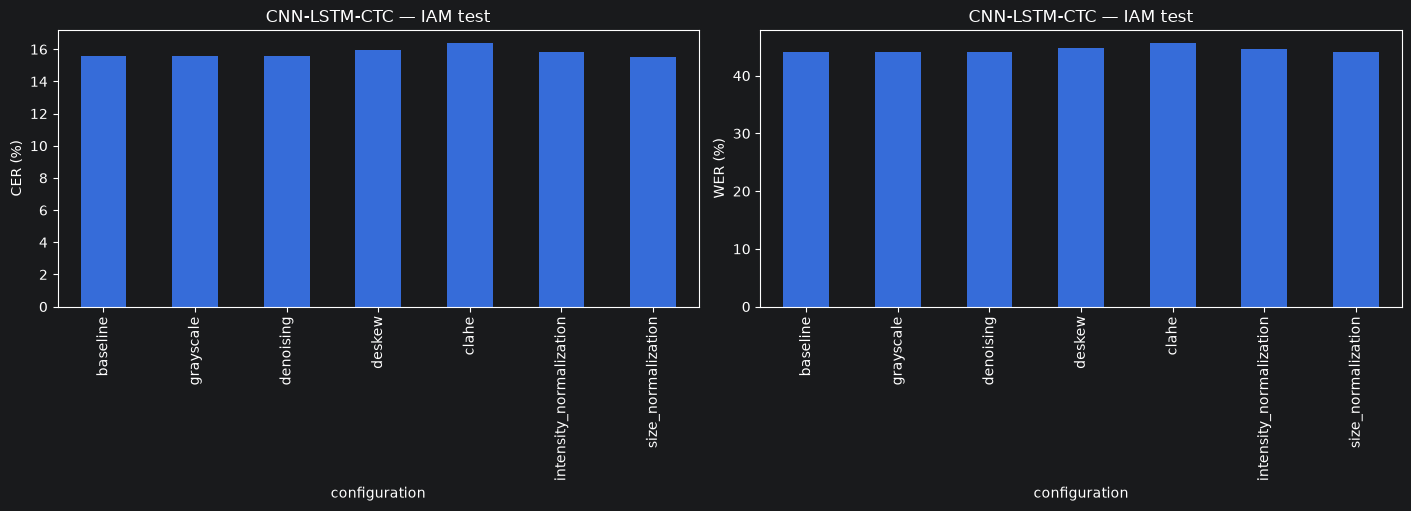

,sample_id,ground_truth,prediction,cer,wer
0,sample_0,"assuredness "" Bella Bella Marie "" ( Parlophone...","assuredness "" Bella bella Marie ( Parlophone ...",0.064516,0.333333
1,sample_6,He is also a director of a couple of garages ....,the is also a director of a couple of garages ...,0.023256,0.047619
2,sample_8,"The numbers include "" Scotland the Brave , "" ""...",The yumbers inelude Scotland the Brave 's a Me...,0.138462,0.466667
3,sample_9,"Fay Compton stars in "" No Hiding Place "" (I T ...","Pay Compton sfars in "" No tiding plave n ( 97 ...",0.253968,0.588235
4,sample_10,She plays the possessive mother of a man whose...,she plays the possessive mathier o a mran whos...,0.163934,0.545455
5,sample_12,"THREE people will be hypnotised in tonight's ""...","THaFE puople wild be hyyyotised in tonightis ""...",0.175439,0.700000
6,sample_13,"( B B C , 10.15 ) .","CPPe , 10.1s ) .",0.421053,0.625000
7,sample_15,of Rhodesia and Nyasaland ( 10.30 p.m. ) .,"if phodes,a and pNyasalond CiOizDpin.g .",0.404762,0.777778
8,sample_17,"playwright Arnold Wesker . "" Instead , Muggeri...","playuright brnokd werker . "" "" Iustead , Mhuyg...",0.190476,0.777778
9,sample_19,will be with Sir Roy Welensky the Premier of t...,will be with Sir Boy weleasky the Premsier of ...,0.118644,0.545455


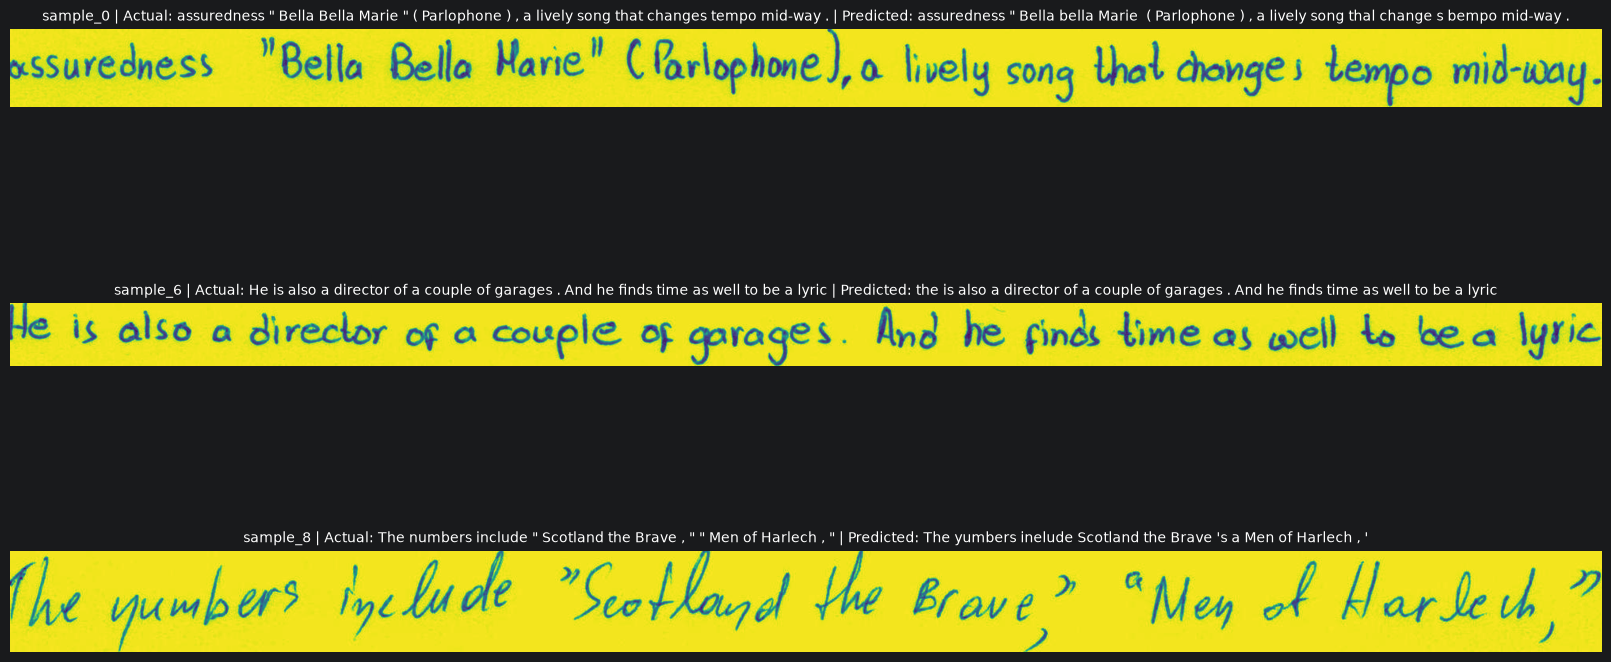

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
for ax, metric in zip(axes, ("cer", "wer")):
    comparison.set_index("configuration")[metric].mul(100).plot.bar(ax=ax)
    ax.set_ylabel(metric.upper() + " (%)")
    ax.set_title("CNN-LSTM-CTC — IAM test")
fig.savefig(OUTPUT_DIR / "cer_wer.png", dpi=160, bbox_inches="tight")
plt.show()
predictions = pd.read_csv(OUTPUT_DIR / "iam/baseline/predictions.csv", keep_default_na=False)
display(predictions[["sample_id", "ground_truth", "prediction", "cer", "wer"]].head(10))
fig, axes = plt.subplots(3, 1, figsize=(16, 8), layout="constrained")
for ax, sample in zip(axes, samples[:3]):
    prediction = predictions.set_index("sample_id").loc[sample["id"], "prediction"]
    ax.imshow(sample["image"])
    ax.set_title(f'{sample["id"]} | Actual: {sample["ground_truth"]} | Predicted: {prediction}', fontsize=10)
    ax.axis("off")
fig.savefig(OUTPUT_DIR / "baseline_examples.png", dpi=160, bbox_inches="tight")
plt.show()